# Flower Classification Project

Your task is to **classify photos of flowers as roses, sunflowers or tulips**, with only 100 photos per kind of flower to learn from, using **transfer learning**.

# The Business Problem

A garden centre runs a website where customers upload a photo of a flower from their garden and receive a care guide for it: when to water, when to cut it back, which pests to watch for. At the moment, a member of staff looks at every photo and chooses the right guide by hand. The garden centre starts with its three most requested guides, **roses, sunflowers and tulips**, and wants a model that chooses the guide automatically from the photo.

Your model answers this question: given a photo, which of the three flowers does it show? A wrong answer sends a customer the wrong care guide, so at the end you look at **which photos the model gets wrong**, so that the garden centre knows when to trust it and when a member of staff should check the answer.

The model can only answer with one of the three flowers. A photo of a daisy would still receive one of the three labels, so the website has to make clear which flowers the service covers.

# Data Description

The data ships with this repository in the folder `data/`: **390 colour photos**, one JPEG file per photo, sorted into one folder per kind of flower. The name of the folder is the label of the photo.

| Folder | Photos | Description |
| :-- | :-- | :-- |
| `data/train/rose` | 100 | roses, for training |
| `data/train/sunflower` | 100 | sunflowers, for training |
| `data/train/tulip` | 100 | tulips, for training |
| `data/validation/rose` | 20 | roses, for choosing the model |
| `data/validation/sunflower` | 20 | sunflowers, for choosing the model |
| `data/validation/tulip` | 20 | tulips, for choosing the model |
| `data/test/rose` | 10 | roses, **the test set** |
| `data/test/sunflower` | 10 | sunflowers, **the test set** |
| `data/test/tulip` | 10 | tulips, **the test set** |

The photos have different sizes, from 159 to 640 pixels wide, and show the flowers in very different ways: a single flower close up, a whole field, a bunch in a vase, sometimes with people or buildings in the picture.

The photos are part of the [TensorFlow flower photos](https://www.tensorflow.org/datasets/catalog/tf_flowers) collection and were taken from Flickr. Every photo is licensed under [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/); its photographer is listed in `data/LICENSE.txt`.

## Task

1. **Get the data.** Display a few photos of every class from `data/train`.
2. **Load the training and the validation images.** Load `data/train` and `data/validation` with `keras.utils.image_dataset_from_directory`, with one `image_size` that you use for every model, for example `(160, 160)`. Shuffle the training images with a fixed `seed`; keep the validation images in their order with `shuffle=False`. Do not load `data/test` until step 6.
3. **Explore the training set.** Display a grid of training photos with their labels. What makes the three flowers look different: colour, shape, the background?
4. **Repurpose a pretrained network.** Use `MobileNetV2` from `keras.applications` as the pretrained network and repurpose it to classify the three flowers. Plot its learning curves: does it overfit?

> [!IMPORTANT]
> **Every image has to be prepared in exactly the same way**: the same `image_size`, the same `preprocess_input` of the base, and the same frozen base, for the training, the validation and later the test images.

5. **If needed, improve the model with data augmentation**, and compare the validation accuracy with step 4. Choose your best model by its validation accuracy. **Save every model to a file** with `model.save`, for example `models/dense_head.keras`, so that you can load all of them in step 6 with `keras.models.load_model`, even after restarting the notebook.
6. **Evaluate all models on the test set at the very end.** Load your saved models, and load `data/test` with the same `image_size` and with `shuffle=False`. Then:
    1. Collect the **validation and test accuracy of every model** in **one table**. Is the validation accuracy of your chosen model a fair estimate of its test accuracy? The test set has only 30 photos, so **one photo changes the test accuracy by 3.3 percentage points**.
    2. **Plot the confusion matrix** of your best model on the test set. Which flowers does it confuse?
    3. **Display every misclassified test photo**, with its true and predicted label. What do these photos have in common?
7. **Try your model in an app.** The repository contains a small [Streamlit](https://docs.streamlit.io/) app, `app.py`, that loads a model from `models/` and classifies a photo that you upload. Start it in a terminal in the repository folder with `uv run streamlit run app.py`, choose your best model, and upload a few flower photos of your own. Does the model get them right? The app works with models that take the raw photos and include their preprocessing, such as `preprocess_input`, as layers.

In [1]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

# One plot style for the whole notebook
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3}
)

In [2]:
# Import Data
CLASSES = ["rose", "sunflower", "tulip"]
flowers = Path("data")

pd.DataFrame(
    {split: {name: len(list((flowers / split / name).glob("*.jpg"))) for name in CLASSES}
     for split in ["train", "validation", "test"]}
)

,train,validation,test
rose,100,20,10
sunflower,100,20,10
tulip,100,20,10


In [3]:
# Load images helper function
def load_images(split, shuffle):
    """Return a dataset of (images, labels) batches for one split of the sea animals."""
    return keras.utils.image_dataset_from_directory(
        flowers / split, image_size=IMAGE_SIZE, batch_size=32, label_mode="int", shuffle=shuffle, seed=42
    )

Found 300 files belonging to 3 classes.
Found 60 files belonging to 3 classes.


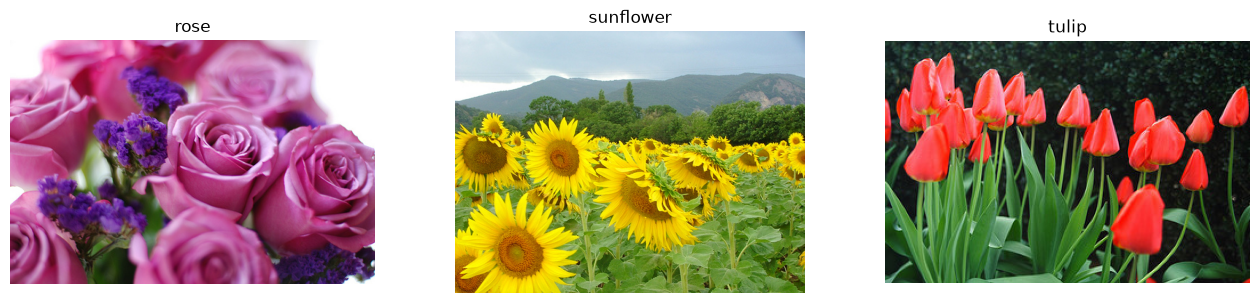

In [4]:
# preview original images from disk
train_ds = load_images("train", shuffle=True)
valid_ds = load_images("validation", shuffle=False)
class_names = train_ds.class_names

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, name in zip(axes, class_names):
    image = keras.utils.load_img(next((flowers / "train" / name).glob("*.jpg")))
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.show()

In [5]:
# check image size inside our data
images, labels = next(iter(train_ds))
images.shape

TensorShape([32, 160, 160, 3])

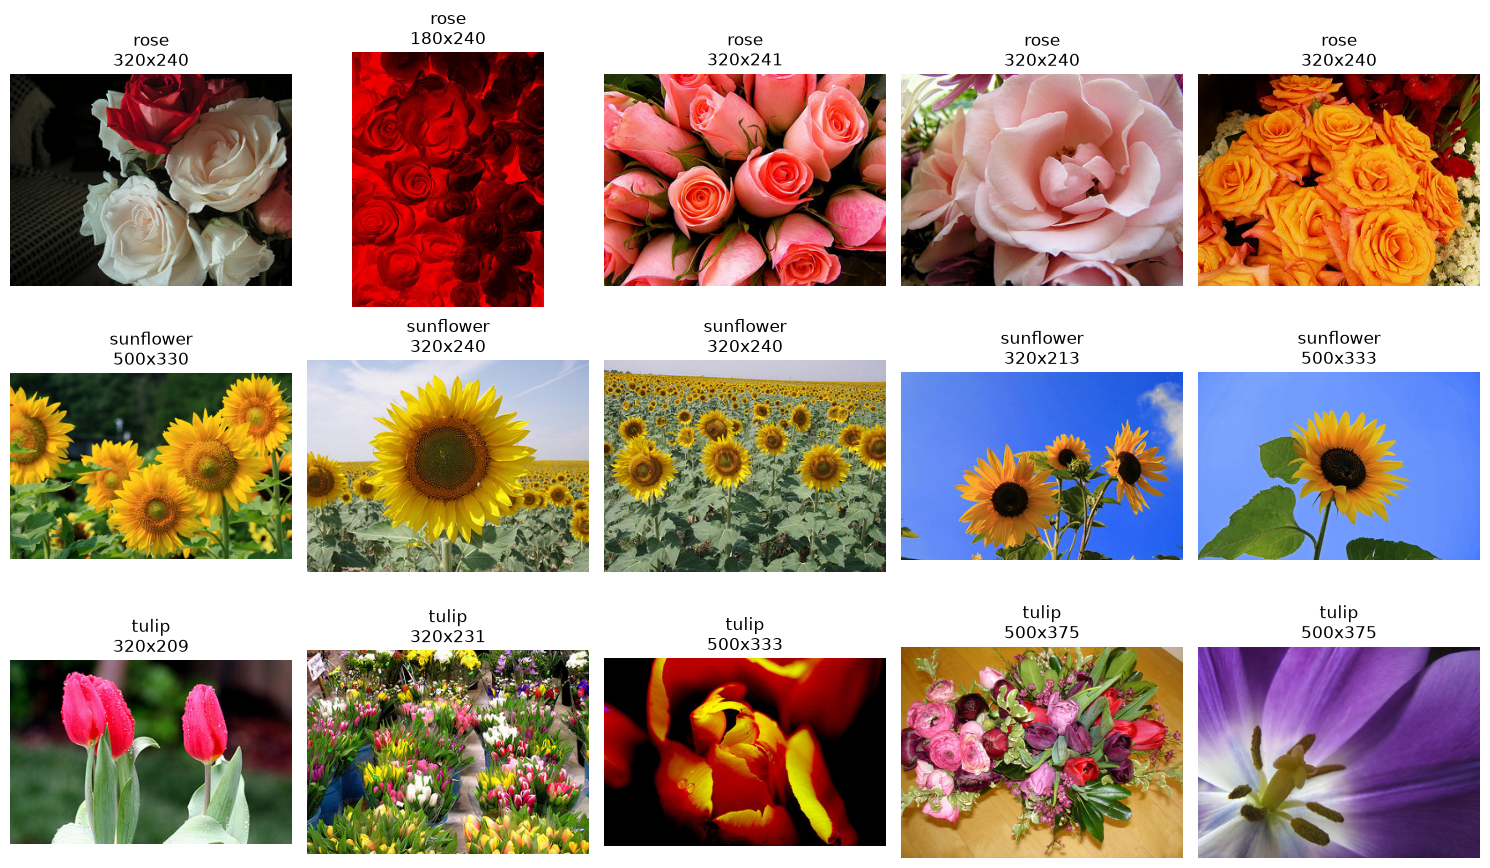

In [6]:
# Show the first 5 photos of every class
n_per_class = 5
fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(15, 9))

for row, flower in enumerate(CLASSES):
    files = sorted(( flowers / "train" / flower).glob("*.jpg"))[:n_per_class]
    for col, file in enumerate(files):
        img = plt.imread(file)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{flower}\n{img.shape[1]}x{img.shape[0]}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

# What mobileNet thinks our images are

In [7]:
base = mobilenet_v2.MobileNetV2(
    include_top=True, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)

Output shape: (32, 1000)
daisy                0.166
hair_slide           0.119
bee                  0.029


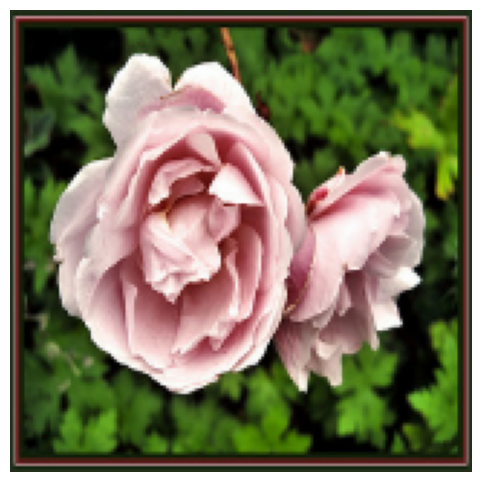

In [8]:
one_image,_ = next(iter(train_ds))

prepared = mobilenet_v2.preprocess_input(one_image)
probabilities = base.predict(prepared, verbose=0)  # shape (1, 1000)
print("Output shape:", probabilities.shape)
for _, name, probability in mobilenet_v2.decode_predictions(probabilities, top=3)[0]:
    print(f"{name:20s} {probability:.3f}")

plt.figure(figsize=(6, 6))
plt.imshow(one_image[0].numpy().astype("uint8"))
plt.axis("off")
plt.show()

# Transfer learning

In [9]:
base2 = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)
base2.trainable = False

In [10]:
# helper function for extraction
def extract_features(dataset):
    """Run the frozen base over every batch of a dataset; return the feature vectors and the labels."""
    all_features = []
    all_labels = []
    for images, labels in dataset:  # one batch of up to 32 images at a time
        images = mobilenet_v2.preprocess_input(images)  # scale the pixels from 0 to 255 to -1 to 1
        features = base2.predict(images, verbose=0)  # one row of 1,280 numbers per image
        all_features.append(features)
        all_labels.append(labels.numpy())
    return np.concatenate(all_features), np.concatenate(all_labels)  # stack the batches into one table


In [11]:
def compile_and_fit(model, epochs, learning_rate=1e-3, initial_epoch=0):
    """Compile a classifier with Adam and train it on the bean images; return the learning curves."""
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        metrics=["accuracy"],
    )
    history = model.fit(
        train_ds, validation_data=valid_ds, epochs=epochs, initial_epoch=initial_epoch, verbose=0
    )
    return pd.DataFrame(history.history, index=history.epoch)


def plot_curves(logs, title):
    """Plot the training and validation loss and accuracy of one run."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title=f"{title}: loss")
    logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title=f"{title}: accuracy")
    plt.show()

# Splitting the data

In [12]:

X_train, y_train = extract_features(load_images("train", shuffle=False))
X_valid, y_valid = extract_features(valid_ds)

print("Training features:", X_train.shape, " validation features:", X_valid.shape)
print('labels', y_train.shape)

Found 300 files belonging to 3 classes.
Training features: (300, 1280)  validation features: (60, 1280)
labels (300,)


In [23]:


keras.utils.clear_session()
keras.utils.set_random_seed(42)

head = keras.Sequential(
    [
        keras.Input(shape=(X_train.shape[1],)),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=len(class_names), activation="softmax", kernel_regularizer=keras.regularizers.L2(.1)),
    ]
)
# compile 
head.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-3), metrics=["accuracy"])
# fitting
head_history = head.fit(X_train, y_train, epochs=30, verbose=0, validation_data=(X_valid, y_valid))

logs = pd.DataFrame(head_history.history, index=head_history.epoch)

In [24]:
test_loss, test_accuracy = head.evaluate(X_valid, y_valid, verbose=0)

print(f"Validation Loss: {test_loss:.4f}")
print(f"Validation Accuracy: {test_accuracy:.4f}")
print(f"Validation Accuracy: {test_accuracy * 100:.2f}%")

Validation Loss: 0.5765
Validation Accuracy: 0.8667
Validation Accuracy: 86.67%


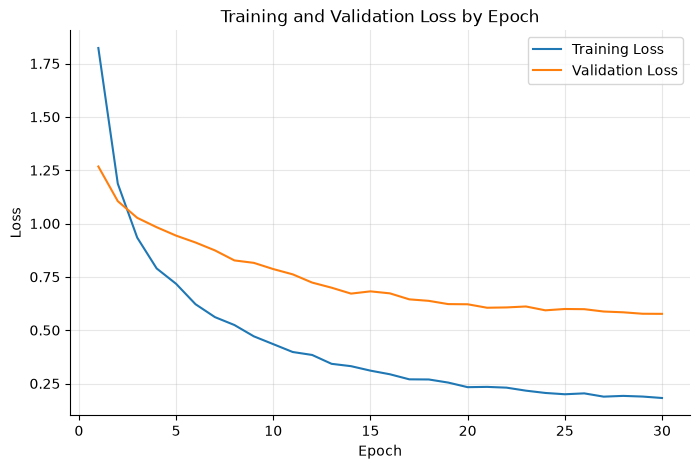

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(logs.index + 1, logs["loss"], label="Training Loss")
plt.plot(logs.index + 1, logs["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss by Epoch")
plt.legend()
plt.grid(True)
plt.show()


/Users/khaldouna/Documents/Neuefische/w5d5/amle-project-flowers/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


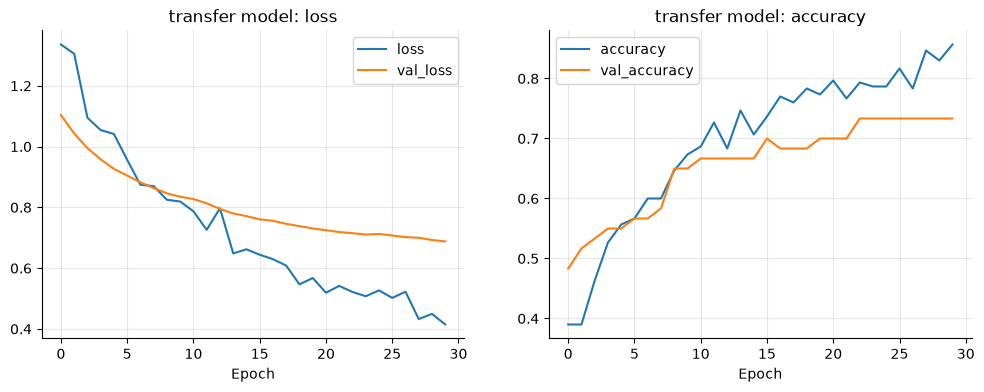

Validation accuracy: 0.733


In [22]:

keras.utils.clear_session()
keras.utils.set_random_seed(42)
augmentation = keras.Sequential(
    [keras.layers.RandomFlip("horizontal"), keras.layers.RandomRotation(0.1), keras.layers.RandomZoom(0.1)]
)
transfer_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        augmentation,
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),
        base2,
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=len(class_names), activation="softmax"),
    ]
)

transfer_model.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-4), metrics=["accuracy"])

history = transfer_model.fit(train_ds, validation_data=valid_ds, epochs=30, verbose=0)

frozen_logs = pd.DataFrame(history.history, index=history.epoch)
plot_curves(frozen_logs, "transfer model")
results={}
results["transfer_model"] = transfer_model.evaluate(valid_ds, verbose=0)[1]
print(f"Validation accuracy: {results['transfer_model']:.3f}")

In [26]:
Path("models").mkdir(exist_ok=True)

head.save("models/dense_head.keras")
transfer_model.save("models/augmented_model.keras")